In [344]:
words = open('names.txt','r').read().splitlines()

In [345]:
words[:10], len(words), min([len(word) for word in words]), max([len(word) for word in words])

(['emma',
  'olivia',
  'ava',
  'isabella',
  'sophia',
  'charlotte',
  'mia',
  'amelia',
  'harper',
  'evelyn'],
 32033,
 2,
 15)

In [346]:
b={}

for w in words:
    chs = ['<S>']+list(w)+["<E>"]
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram=(ch1,ch2)
        b[bigram]=b.get(bigram,0)+1
        print(ch1,ch2)

<S> e
e m
m m
m a
a <E>
<S> o
o l
l i
i v
v i
i a
a <E>
<S> a
a v
v a
a <E>
<S> i
i s
s a
a b
b e
e l
l l
l a
a <E>
<S> s
s o
o p
p h
h i
i a
a <E>
<S> c
c h
h a
a r
r l
l o
o t
t t
t e
e <E>
<S> m
m i
i a
a <E>
<S> a
a m
m e
e l
l i
i a
a <E>
<S> h
h a
a r
r p
p e
e r
r <E>
<S> e
e v
v e
e l
l y
y n
n <E>
<S> a
a b
b i
i g
g a
a i
i l
l <E>
<S> e
e m
m i
i l
l y
y <E>
<S> e
e l
l i
i z
z a
a b
b e
e t
t h
h <E>
<S> m
m i
i l
l a
a <E>
<S> e
e l
l l
l a
a <E>
<S> a
a v
v e
e r
r y
y <E>
<S> s
s o
o f
f i
i a
a <E>
<S> c
c a
a m
m i
i l
l a
a <E>
<S> a
a r
r i
i a
a <E>
<S> s
s c
c a
a r
r l
l e
e t
t t
t <E>
<S> v
v i
i c
c t
t o
o r
r i
i a
a <E>
<S> m
m a
a d
d i
i s
s o
o n
n <E>
<S> l
l u
u n
n a
a <E>
<S> g
g r
r a
a c
c e
e <E>
<S> c
c h
h l
l o
o e
e <E>
<S> p
p e
e n
n e
e l
l o
o p
p e
e <E>
<S> l
l a
a y
y l
l a
a <E>
<S> r
r i
i l
l e
e y
y <E>
<S> z
z o
o e
e y
y <E>
<S> n
n o
o r
r a
a <E>
<S> l
l i
i l
l y
y <E>
<S> e
e l
l e
e a
a n
n o
o r
r <E>
<S> h
h a
a n
n n
n a
a 

In [347]:
x = sorted(b.items(), key = lambda kv: kv[1], reverse=True)
x

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [348]:
import torch
a = torch.zeros((27,27), dtype=torch.int32)
a.shape

torch.Size([27, 27])

In [349]:
chars=sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {s:i for i,s in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [350]:
for word in words:
    chs = ['.']+list(word)+['.']
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        a[ix1,ix2]+=1

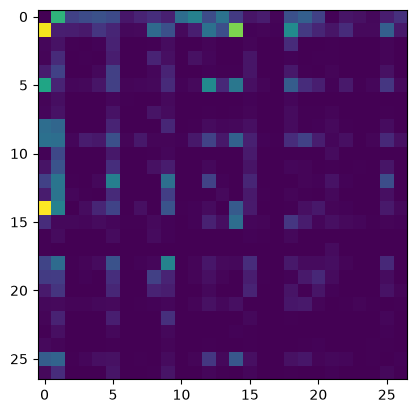

In [351]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(a)

In [352]:
p=a[0].float()
p=p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [353]:
g = torch.Generator().manual_seed(2)
p = torch.rand(4,generator=g)
p = p/p.sum()
p

tensor([0.2917, 0.1808, 0.3023, 0.2252])

In [354]:
g = torch.Generator().manual_seed(2)
ix = torch.multinomial(p,num_samples=1,replacement=True, generator=g).item()
# ix=torch.multinomial(p,num_samples=1,replacement=False,generator=g).item()
itos[ix]

'a'

In [355]:
P = (a+1).float()
P /=P.sum(-1,keepdim=True)
P[0].sum()

tensor(1.)

In [356]:
g = torch.Generator().manual_seed(2)
for i in range(10):
    out=[]
    ix=0
    while True:
        p=P[ix]
        ix=torch.multinomial(p,num_samples=1,replacement=False,generator=g).item()
        out.append(itos[ix])
        # print(itos[ix])
        if ix==0:
            break
    print("".join(out))


an.
zan.
an.
deveerhacarolyme.
an.
myn.
ayenn.
d.
b.
monan.


In [357]:
ll=0.0
n=0

for word in words[:3]:
    chs = ['.']+list(word)+['.']
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob=P[ix1,ix2]
        log = torch.log(prob)
        n+=1
        ll+=log
        print(f"{ch1,ch2},{prob:.4f},{-log:.4f}")
nll=-ll
print(nll)
print(nll/n)

('.', 'e'),0.0478,3.0410
('e', 'm'),0.0377,3.2793
('m', 'm'),0.0253,3.6753
('m', 'a'),0.3885,0.9454
('a', '.'),0.1958,1.6305
('.', 'o'),0.0123,4.3965
('o', 'l'),0.0779,2.5526
('l', 'i'),0.1774,1.7293
('i', 'v'),0.0152,4.1845
('v', 'i'),0.3508,1.0476
('i', 'a'),0.1380,1.9807
('a', '.'),0.1958,1.6305
('.', 'a'),0.1376,1.9835
('a', 'v'),0.0246,3.7041
('v', 'a'),0.2473,1.3971
('a', '.'),0.1958,1.6305
tensor(38.8086)
tensor(2.4255)


In [358]:
xs,ys = [],[]
for w in words:
    chs = ['.']+list(w)+['.']
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

In [359]:
xs, ys
num = xs.nelement()

In [360]:
import torch.nn.functional as F
xenc = F.one_hot(xs,num_classes=27).float()

g = torch.Generator().manual_seed(2)
W = torch.randn((27,27),generator=g,requires_grad=True)

In [364]:
for i in range(1000):
    logits=(xenc@W)
    counts = logits.exp()
    prob = counts/counts.sum(1,keepdim=True)
    loss=-prob[torch.arange(num),ys].log().mean()
    W.grad=None
    loss.backward()
    W.data+=-1*W.grad
    print(i,loss)# prob

0 tensor(2.5695, grad_fn=<NegBackward0>)
1 tensor(2.5694, grad_fn=<NegBackward0>)
2 tensor(2.5692, grad_fn=<NegBackward0>)
3 tensor(2.5691, grad_fn=<NegBackward0>)
4 tensor(2.5690, grad_fn=<NegBackward0>)
5 tensor(2.5689, grad_fn=<NegBackward0>)
6 tensor(2.5688, grad_fn=<NegBackward0>)
7 tensor(2.5686, grad_fn=<NegBackward0>)
8 tensor(2.5685, grad_fn=<NegBackward0>)
9 tensor(2.5684, grad_fn=<NegBackward0>)
10 tensor(2.5683, grad_fn=<NegBackward0>)
11 tensor(2.5682, grad_fn=<NegBackward0>)
12 tensor(2.5680, grad_fn=<NegBackward0>)
13 tensor(2.5679, grad_fn=<NegBackward0>)
14 tensor(2.5678, grad_fn=<NegBackward0>)
15 tensor(2.5677, grad_fn=<NegBackward0>)
16 tensor(2.5676, grad_fn=<NegBackward0>)
17 tensor(2.5675, grad_fn=<NegBackward0>)
18 tensor(2.5673, grad_fn=<NegBackward0>)
19 tensor(2.5672, grad_fn=<NegBackward0>)
20 tensor(2.5671, grad_fn=<NegBackward0>)
21 tensor(2.5670, grad_fn=<NegBackward0>)
22 tensor(2.5669, grad_fn=<NegBackward0>)
23 tensor(2.5668, grad_fn=<NegBackward0>)
24

In [365]:
prob

tensor([[0.0025, 0.1374, 0.0404,  ..., 0.0055, 0.0163, 0.0287],
        [0.1945, 0.0324, 0.0070,  ..., 0.0058, 0.0518, 0.0099],
        [0.0630, 0.3820, 0.0171,  ..., 0.0041, 0.0337, 0.0097],
        ...,
        [0.2041, 0.2180, 0.0050,  ..., 0.0084, 0.0058, 0.0089],
        [0.0517, 0.3316, 0.0112,  ..., 0.0172, 0.0449, 0.0281],
        [0.0720, 0.0418, 0.0316,  ..., 0.0524, 0.0419, 0.0517]],
       grad_fn=<DivBackward0>)

In [377]:
for i in range(5):
    out = []
    z=0
    while True:
        logits = xenc@W
        counts = logits.exp()
        prob = counts /counts.sum(1,keepdim=True)
        p = prob[z]
        z = torch.multinomial(p, num_samples=1,replacement=True).item()
        out.append(itos[z])
        if z==0:
            break
    print("".join(out))


byykrtlaypralneryknmnia.
kh.
mviiks.
aknvaemnedzmnarunm.
k.
